# TA-05: Klasifikasi Jamur Beracun dan Bisa Dimakan dengan Decision Tree

**Mata praktikum:** Pembelajaran Mesin | **Modul 05:** Algoritma Decision Tree
**Dataset:** Mushroom Classification (UCI) | 8.124 sampel, 22 fitur kategorikal, 1 target (`class`)

Alur notebook ini mengikuti langkah-langkah TA-05:

1. Memuat ulang dataset dari TP-05
2. EDA dan pra-pemrosesan (nilai hilang, fitur kategorikal)
3. Model A (tanpa batasan) dan Model B (di-pruning)
4. Evaluasi dan perbandingan kedua model
5. Visualisasi pohon, aturan jika-maka, dan feature importance (fokus Model B)
6. Penyimpanan model dengan Joblib untuk aplikasi Flask

## 1. Persiapan dan memuat dataset

In [1]:
import os, sys, json, warnings
sys.path.append("..")                      # agar labels.py (kamus label Indonesia) bisa diimpor
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Patch
from matplotlib.colors import to_rgb

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import joblib

from labels import FEATURES, FITUR_MODEL, KELAS, short, judul_pendek, jelaskan_kondisi, pisah_ohe

os.makedirs("../figures", exist_ok=True)
os.makedirs("../model", exist_ok=True)

RANDOM_STATE = 42
# Warna konsisten di seluruh grafik: biru = bisa dimakan, oranye = beracun
BIRU, ORANYE = "#2a78d6", "#eb6834"
PAL = {"e": BIRU, "p": ORANYE}
INK, INK2, GRID, AXIS = "#0b0b0b", "#52514e", "#e1e0d9", "#c3c2b7"

plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2, "text.color": INK,
    "axes.edgecolor": AXIS, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.axisbelow": True, "legend.frameon": False, "savefig.dpi": 200, "savefig.bbox": "tight",
})

def simpan(nama):
    plt.savefig(f"../figures/{nama}.png")
    plt.show()

df = pd.read_csv("../data/mushrooms.csv")
print("Ukuran data:", df.shape)
df.head()

Ukuran data: (8124, 23)


,class,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
0,p,x,s,n,t,p,f,c,n,k,...,s,w,w,p,w,o,p,k,s,u
1,e,x,s,y,t,a,f,c,b,k,...,s,w,w,p,w,o,p,n,n,g
2,e,b,s,w,t,l,f,c,b,n,...,s,w,w,p,w,o,p,n,n,m
3,p,x,y,w,t,p,f,c,n,n,...,s,w,w,p,w,o,p,k,s,u
4,e,x,s,g,f,n,f,w,b,k,...,s,w,w,p,w,o,e,n,a,g


## 2. Eksplorasi data (EDA)

### 2.1 Informasi dasar dan pemeriksaan nilai hilang

In [2]:
print("Tipe data      :", df.dtypes.value_counts().to_dict())
print("Nilai NaN total:", int(df.isnull().sum().sum()))

# Nilai hilang pada dataset ini ditulis sebagai simbol '?', sehingga isnull() tidak menangkapnya
tanda_tanya = (df == "?").sum()
tanda_tanya = tanda_tanya[tanda_tanya > 0]
print("\nKolom dengan nilai '?':")
print(tanda_tanya.to_string())
print(f"Persentase stalk-root yang hilang: {tanda_tanya['stalk-root'] / len(df):.1%}")

print("\nJumlah nilai unik per kolom (terkecil):")
print(df.nunique().sort_values().head(4).to_string())

Tipe data      : {<StringDtype(storage='python', na_value=nan)>: 23}
Nilai NaN total: 0

Kolom dengan nilai '?':
stalk-root    2480
Persentase stalk-root yang hilang: 30.5%

Jumlah nilai unik per kolom (terkecil):
veil-type          1
class              2
gill-attachment    2
gill-spacing       2


**Temuan:**

- `isnull()` melaporkan 0 nilai hilang, tetapi kolom `stalk-root` berisi **2.480 simbol `?`** (sekitar 30,5%) yang sebenarnya adalah nilai hilang.
- Kolom `veil-type` hanya punya **satu nilai unik** (`p`), jadi tidak membawa informasi untuk membedakan kelas dan akan dibuang.
- Semua kolom bertipe kategorikal (kode huruf), sehingga perlu di-encode sebelum masuk ke model.

### 2.2 Distribusi variabel target

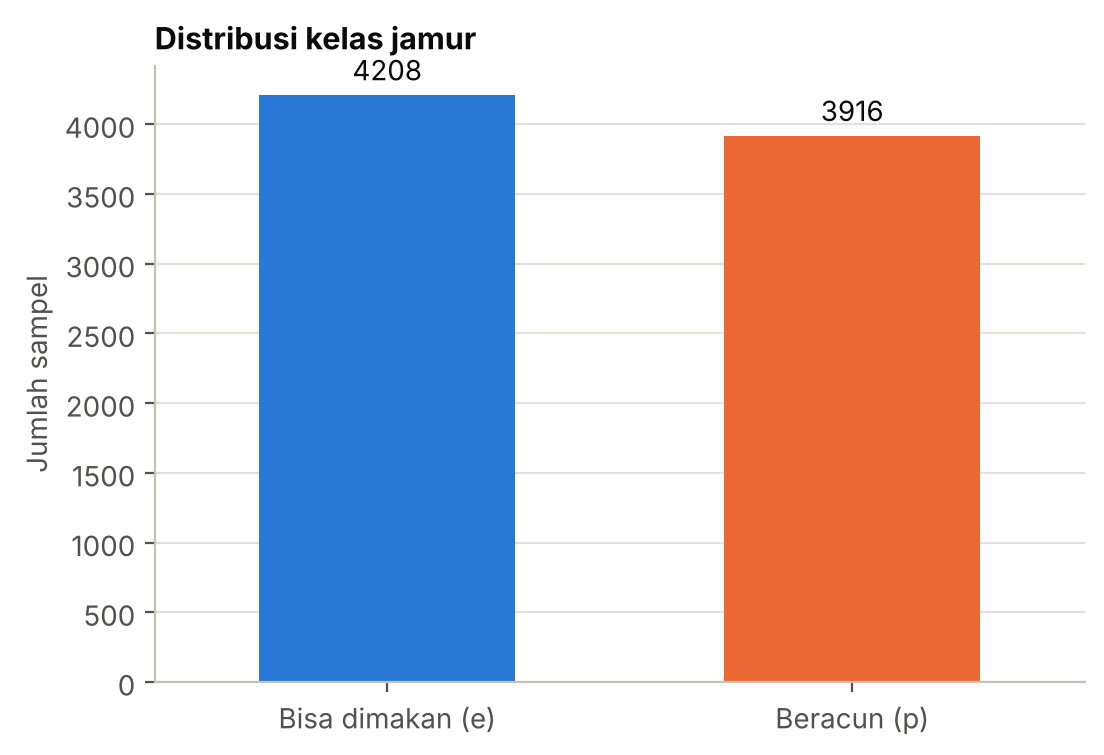

class
bisa dimakan    0.518
beracun         0.482


In [3]:
fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(data=df, x="class", hue="class", order=["e", "p"], palette=PAL, saturation=1, ax=ax, legend=False, width=0.55)
ax.bar_label(ax.containers[0], padding=3); ax.bar_label(ax.containers[1], padding=3)
ax.set_xticks([0, 1]); ax.set_xticklabels(["Bisa dimakan (e)", "Beracun (p)"])
ax.set_title("Distribusi kelas jamur"); ax.set_xlabel(""); ax.set_ylabel("Jumlah sampel")
simpan("01_distribusi_kelas")
print(df["class"].value_counts(normalize=True).round(4).rename({"e": "bisa dimakan", "p": "beracun"}).to_string())

Kelas hampir seimbang (51,8% vs 48,2%), sehingga **akurasi adalah metrik yang adil** dan tidak perlu teknik penyeimbangan data.

### 2.3 Hubungan fitur dengan target

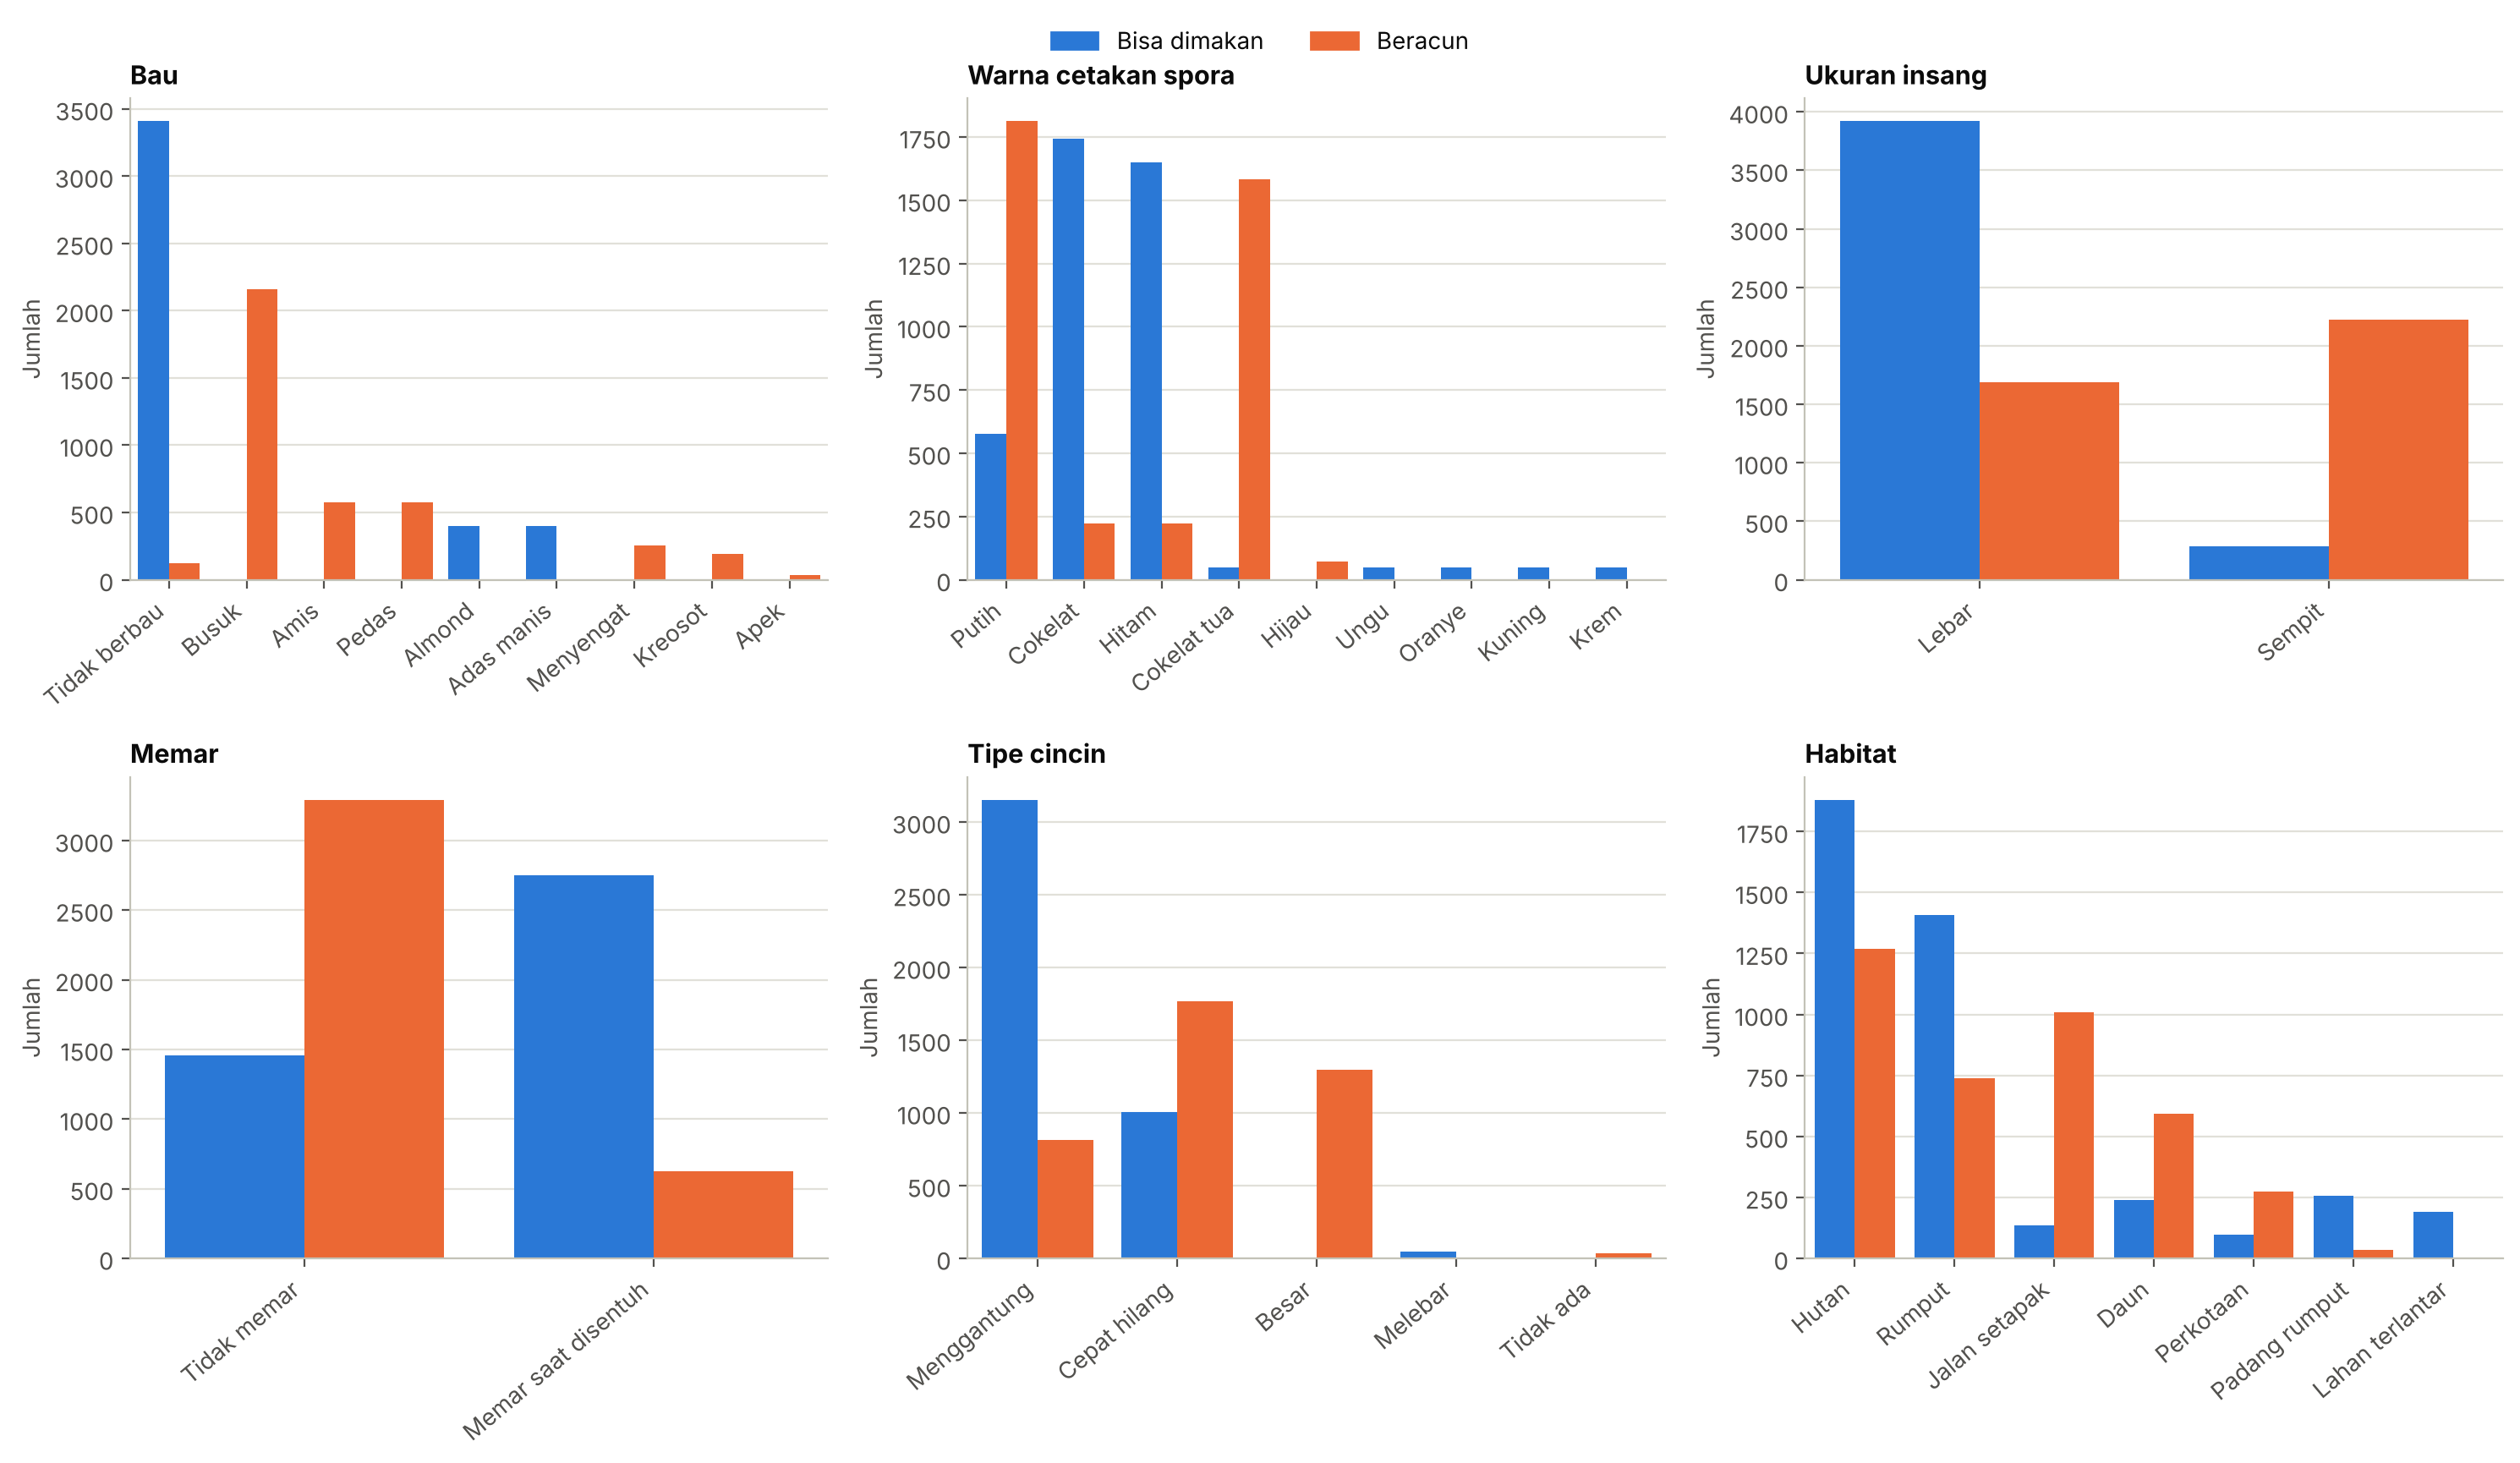

In [4]:
fitur_eda = ["odor", "spore-print-color", "gill-size", "bruises", "ring-type", "habitat"]
fig, axes = plt.subplots(2, 3, figsize=(15, 8.5))
for ax, f in zip(axes.ravel(), fitur_eda):
    urutan = df[f].value_counts().index
    sns.countplot(data=df, x=f, hue="class", order=urutan, hue_order=["e", "p"], palette=PAL, saturation=1, ax=ax, legend=False)
    ax.set_xticks(range(len(urutan)))
    ax.set_xticklabels([short(FEATURES[f][2][k]) for k in urutan], rotation=40, ha="right")
    ax.set_title(judul_pendek(f)); ax.set_xlabel(""); ax.set_ylabel("Jumlah")
fig.legend(handles=[Patch(color=BIRU, label="Bisa dimakan"), Patch(color=ORANYE, label="Beracun")],
           loc="upper center", ncol=2, bbox_to_anchor=(0.5, 1.02))
fig.tight_layout()
simpan("02_fitur_vs_target")

In [5]:
# Contoh tabel silang: bau jamur vs kelas
tabel_bau = pd.crosstab(df["odor"].map(lambda k: short(FEATURES["odor"][2][k])), df["class"].map(KELAS))
tabel_bau

class,Beracun,Bisa dimakan
odor,,
Adas manis,0,400
Almond,0,400
Amis,576,0
Apek,36,0
Busuk,2160,0
Kreosot,192,0
Menyengat,256,0
Pedas,576,0
Tidak berbau,120,3408


Beberapa kategori **hampir murni** pada satu kelas. Misalnya jamur berbau busuk, amis, menyengat, atau berbau kreosot selalu beracun, sedangkan jamur berbau almond atau adas manis selalu bisa dimakan. Inilah alasan Decision Tree cocok untuk dataset ini.

### 2.4 Fitur mana yang paling baik memisahkan kelas?

Gini awal (sebelum dipisah): 0.499


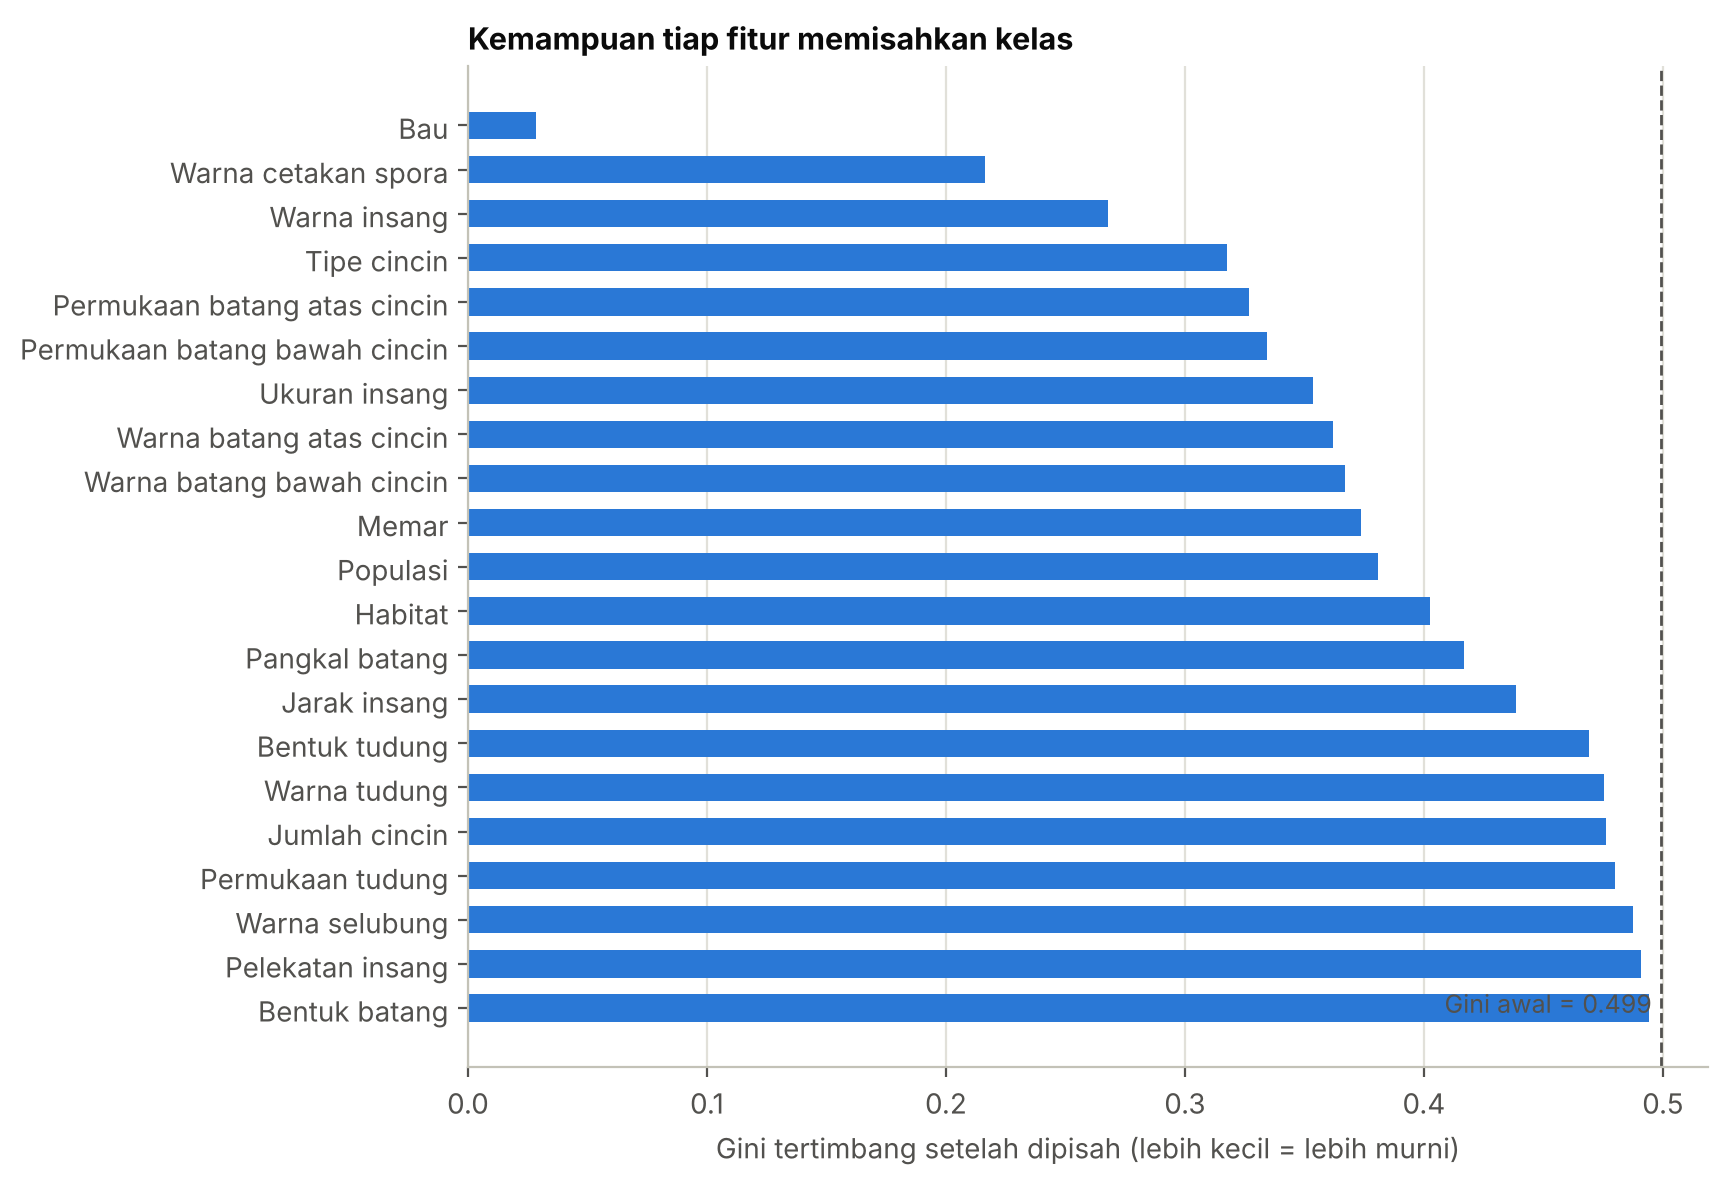

,gini_tertimbang
odor,0.029
spore-print-color,0.216
gill-color,0.268
ring-type,0.318
stalk-surface-above-ring,0.327


In [6]:
def gini_tertimbang(kolom):
    # Gini rata-rata (tertimbang jumlah sampel) setelah data dipisah berdasarkan kategori fitur.
    # Semakin kecil, semakin murni kelompok hasil pemisahan.
    prop = df.groupby(kolom)["class"].value_counts(normalize=True).unstack(fill_value=0)
    n = df[kolom].value_counts().reindex(prop.index)
    return float(((1 - (prop ** 2).sum(axis=1)) * n / len(df)).sum())

gini_fitur = pd.Series({f: gini_tertimbang(f) for f in FITUR_MODEL}).sort_values()
gini_awal = 1 - (df["class"].value_counts(normalize=True) ** 2).sum()
print(f"Gini awal (sebelum dipisah): {gini_awal:.3f}")

fig, ax = plt.subplots(figsize=(8, 6.5))
y_pos = np.arange(len(gini_fitur))[::-1]
ax.barh(y_pos, gini_fitur.values, color=BIRU, height=0.62)
ax.set_yticks(y_pos); ax.set_yticklabels([judul_pendek(f) for f in gini_fitur.index])
ax.axvline(gini_awal, color=INK2, lw=1, ls="--")
ax.text(gini_awal - 0.004, y_pos[-1] + 0.1, f"Gini awal = {gini_awal:.3f}", ha="right", va="center", fontsize=9, color=INK2)
ax.set_xlabel("Gini tertimbang setelah dipisah (lebih kecil = lebih murni)")
ax.set_title("Kemampuan tiap fitur memisahkan kelas"); ax.grid(axis="y", visible=False); ax.grid(axis="x")
simpan("03_gini_per_fitur")
gini_fitur.head(5).round(3).to_frame("gini_tertimbang")

## 3. Pra-pemrosesan data

Strategi yang dipakai:

| Masalah | Penanganan |
|---|---|
| `stalk-root` berisi `?` (30,5%) | Diisi dengan **modus** (nilai terbanyak) memakai `SimpleImputer` |
| Semua fitur kategorikal | **One-Hot Encoding** memakai `OneHotEncoder` |
| `veil-type` hanya 1 nilai unik | Dibuang |
| Target `class` (e/p) | Diubah menjadi 0 = bisa dimakan, 1 = beracun |

Imputasi dan encoding dimasukkan ke dalam satu **Pipeline** bersama model. Dengan begitu, aplikasi Flask cukup memanggil `pipeline.predict()` pada input mentah (kode huruf), tanpa mengulang pra-pemrosesan secara manual dan tanpa risiko tidak konsisten dengan saat pelatihan.

In [7]:
df_model = df.drop(columns=["veil-type"])
X = df_model.drop(columns="class")
y = (df_model["class"] == "p").astype(int)     # 0 = bisa dimakan, 1 = beracun

modus_stalk_root = X.loc[X["stalk-root"] != "?", "stalk-root"].mode()[0]
print("Modus stalk-root (pengisi nilai hilang):", modus_stalk_root, "->", FEATURES["stalk-root"][2][modus_stalk_root])
print("Jumlah fitur setelah veil-type dibuang :", X.shape[1])

def bangun_model(**param_pohon):
    pra = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent", missing_values="?")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ])
    return Pipeline([("pra", pra), ("pohon", DecisionTreeClassifier(random_state=RANDOM_STATE, **param_pohon))])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=RANDOM_STATE, stratify=y)
print(f"\nData latih: {len(X_train)} | Data uji: {len(X_test)}")
print("Proporsi beracun -> latih: {:.3f} | uji: {:.3f}".format(y_train.mean(), y_test.mean()))

Modus stalk-root (pengisi nilai hilang): b -> Membulat (bulbous)
Jumlah fitur setelah veil-type dibuang : 21

Data latih: 5686 | Data uji: 2438
Proporsi beracun -> latih: 0.482 | uji: 0.482


Pembagian data 70:30 memakai `stratify=y` agar proporsi kelas di data latih dan uji tetap sama.

## 4. Pengembangan model

- **Model A (potensi overfit):** `max_depth=None`, pohon dibiarkan tumbuh sampai semua daun murni.
- **Model B (di-pruning):** `max_depth=4`, pohon dibatasi kedalamannya.

In [8]:
model_a = bangun_model()                    # tanpa batasan apa pun
model_b = bangun_model(max_depth=4)         # pre-pruning
model_a.fit(X_train, y_train)
model_b.fit(X_train, y_train)

for nama, m in [("Model A (tanpa batas)", model_a), ("Model B (max_depth=4)", model_b)]:
    pohon = m.named_steps["pohon"]
    print(f"{nama:24s} kedalaman={pohon.get_depth()}  jumlah daun={pohon.get_n_leaves()}  "
          f"jumlah node={pohon.tree_.node_count}")

Model A (tanpa batas)    kedalaman=6  jumlah daun=13  jumlah node=25
Model B (max_depth=4)    kedalaman=4  jumlah daun=11  jumlah node=21


## 5. Evaluasi dan perbandingan model

In [9]:
NAMA_KELAS = ["Bisa dimakan", "Beracun"]
hasil = {}
for kode, nama, m in [("A", "Model A (tanpa batas)", model_a), ("B", "Model B (max_depth=4)", model_b)]:
    pred_train, pred_test = m.predict(X_train), m.predict(X_test)
    cm = confusion_matrix(y_test, pred_test)
    hasil[kode] = dict(
        acc_train=accuracy_score(y_train, pred_train), acc_test=accuracy_score(y_test, pred_test),
        cm=cm.tolist(), pred_test=pred_test,
        depth=m.named_steps["pohon"].get_depth(), leaves=int(m.named_steps["pohon"].get_n_leaves()))
    print("=" * 62)
    print(nama)
    print("=" * 62)
    print(f"Akurasi data latih: {hasil[kode]['acc_train']:.4f}")
    print(f"Akurasi data uji  : {hasil[kode]['acc_test']:.4f}")
    print("\n--- Confusion Matrix (baris = sebenarnya, kolom = prediksi) ---")
    print(cm)
    print("\n--- Classification Report ---")
    print(classification_report(y_test, pred_test, target_names=NAMA_KELAS, digits=4))

Model A (tanpa batas)
Akurasi data latih: 1.0000
Akurasi data uji  : 1.0000

--- Confusion Matrix (baris = sebenarnya, kolom = prediksi) ---
[[1263    0]
 [   0 1175]]

--- Classification Report ---
              precision    recall  f1-score   support

Bisa dimakan     1.0000    1.0000    1.0000      1263
     Beracun     1.0000    1.0000    1.0000      1175

    accuracy                         1.0000      2438
   macro avg     1.0000    1.0000    1.0000      2438
weighted avg     1.0000    1.0000    1.0000      2438



Model B (max_depth=4)
Akurasi data latih: 0.9998
Akurasi data uji  : 0.9988

--- Confusion Matrix (baris = sebenarnya, kolom = prediksi) ---
[[1263    0]
 [   3 1172]]

--- Classification Report ---
              precision    recall  f1-score   support

Bisa dimakan     0.9976    1.0000    0.9988      1263
     Beracun     1.0000    0.9974    0.9987      1175

    accuracy                         0.9988      2438
   macro avg     0.9988    0.9987    0.9988      2438
weighted avg     0.9988    0.9988    0.9988      2438



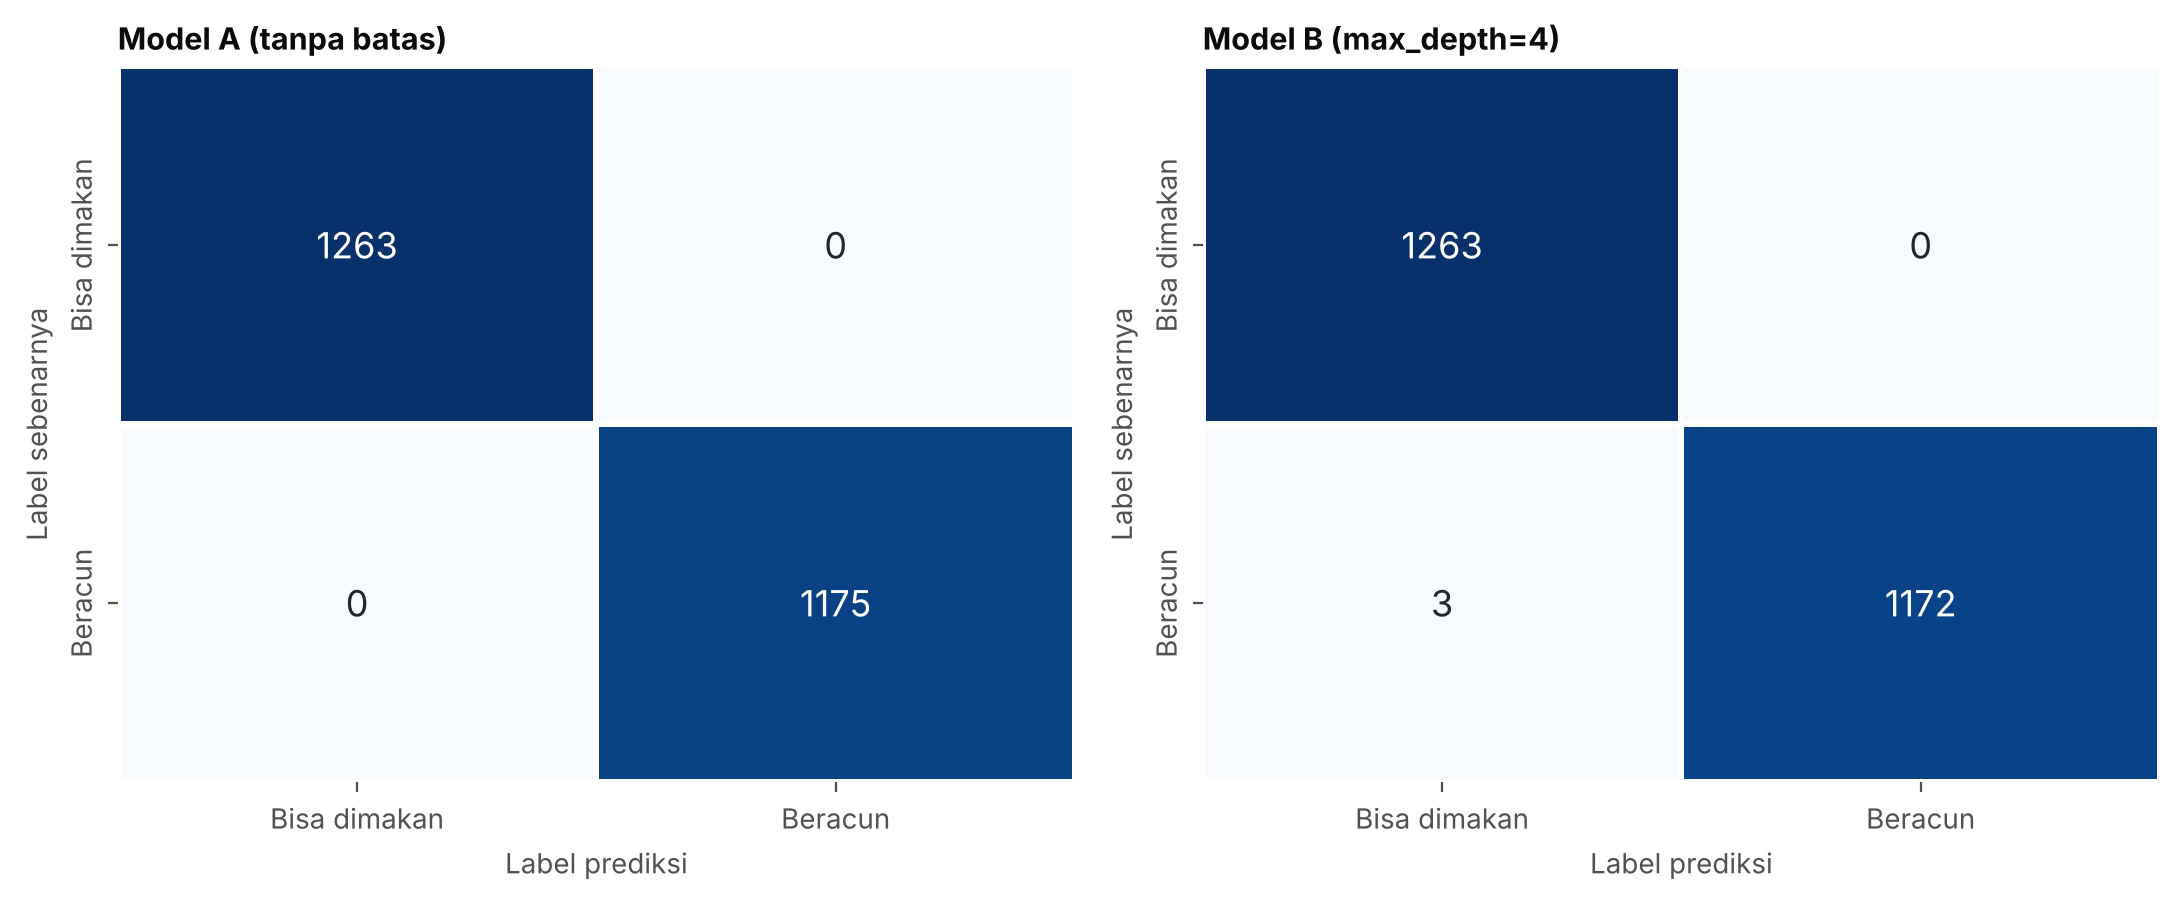

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
for ax, kode, judul in zip(axes, ["A", "B"], ["Model A (tanpa batas)", "Model B (max_depth=4)"]):
    sns.heatmap(np.array(hasil[kode]["cm"]), annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=NAMA_KELAS, yticklabels=NAMA_KELAS, linewidths=2, linecolor="white",
                annot_kws={"fontsize": 13})
    ax.set_title(judul); ax.set_xlabel("Label prediksi"); ax.set_ylabel("Label sebenarnya")
    ax.grid(False)
fig.tight_layout()
simpan("04_confusion_matrix")

### 5.1 Apakah Model A overfit? Menyapu nilai `max_depth`

 max_depth  akurasi_latih  akurasi_uji
         1         0.8881       0.8835
         2         0.9483       0.9418
         3         0.9875       0.9848
         4         0.9998       0.9988
         5         0.9998       0.9988
         6         1.0000       1.0000
         7         1.0000       1.0000
         8         1.0000       1.0000


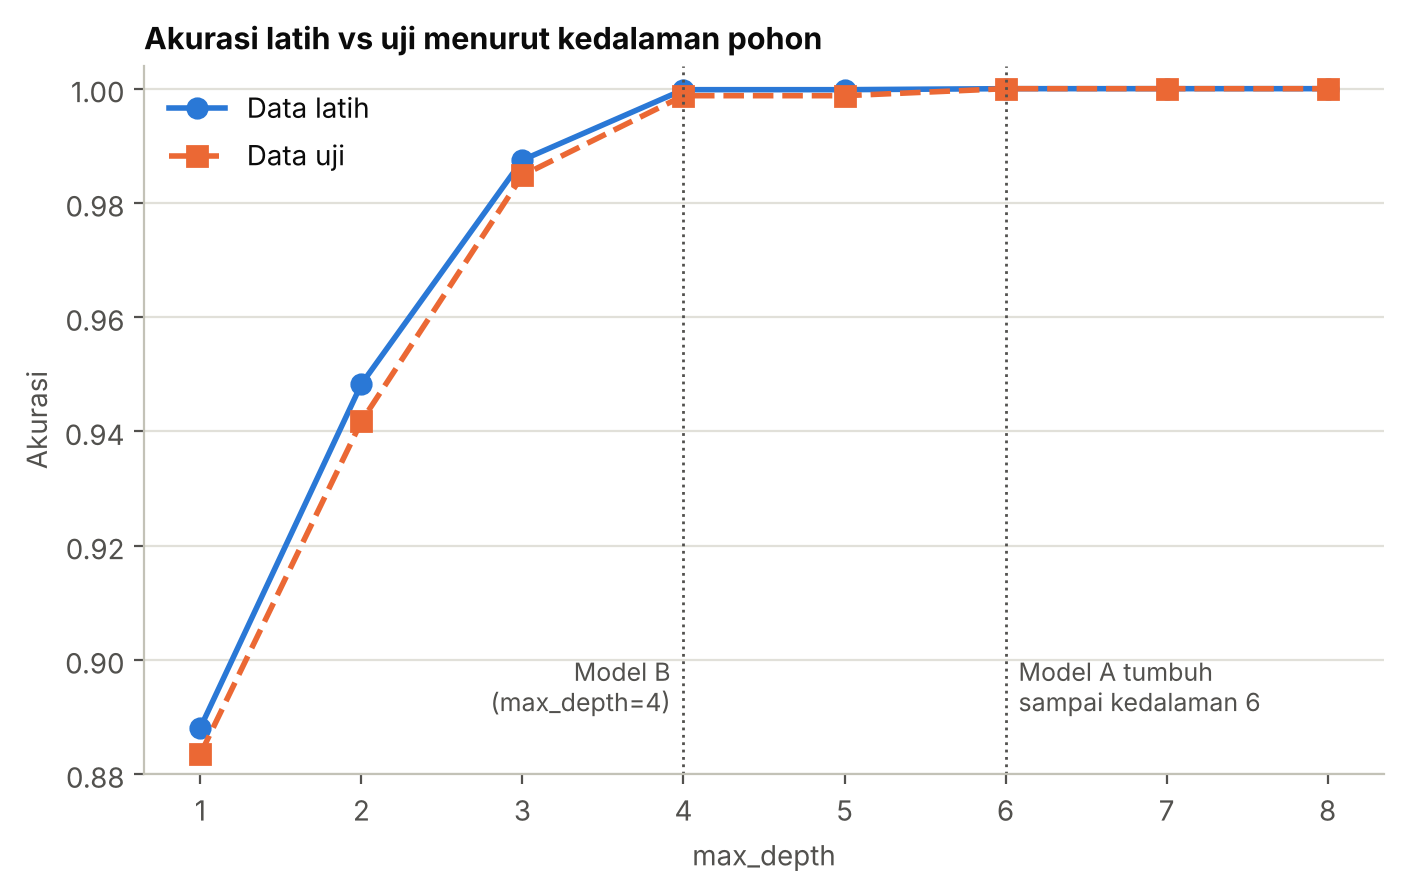

In [11]:
rentang = list(range(1, 9))
latih, uji = [], []
for d in rentang:
    m = bangun_model(max_depth=d).fit(X_train, y_train)
    latih.append(accuracy_score(y_train, m.predict(X_train)))
    uji.append(accuracy_score(y_test, m.predict(X_test)))
sapuan = pd.DataFrame({"max_depth": rentang, "akurasi_latih": latih, "akurasi_uji": uji}).round(4)
print(sapuan.to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 4.6))
ax.plot(rentang, latih, color=BIRU, lw=2, marker="o", ms=7, label="Data latih")
ax.plot(rentang, uji, color=ORANYE, lw=2, marker="s", ms=7, ls="--", label="Data uji")
ax.axvline(4, color=INK2, lw=1, ls=":")
ax.text(3.92, 0.89, "Model B\n(max_depth=4)", fontsize=9, color=INK2, va="bottom", ha="right")
ax.axvline(hasil["A"]["depth"], color=INK2, lw=1, ls=":")
ax.text(hasil["A"]["depth"] + 0.08, 0.89, f"Model A tumbuh\nsampai kedalaman {hasil['A']['depth']}", fontsize=9, color=INK2, va="bottom", ha="left")
ax.set_ylim(0.88, 1.004); ax.set_xticks(rentang)
ax.set_xlabel("max_depth"); ax.set_ylabel("Akurasi")
ax.set_title("Akurasi latih vs uji menurut kedalaman pohon")
ax.legend(loc="upper left")
simpan("05_kurva_kedalaman")

In [12]:
# Validasi silang 5-fold (data diacak agar tiap fold mewakili data secara merata)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_a = cross_val_score(bangun_model(), X, y, cv=skf)
cv_b = cross_val_score(bangun_model(max_depth=4), X, y, cv=skf)

perbandingan = pd.DataFrame({
    "Model A (tanpa batas)": [hasil["A"]["depth"], hasil["A"]["leaves"], hasil["A"]["acc_train"], hasil["A"]["acc_test"],
                              cv_a.mean(), cv_a.std(), hasil["A"]["cm"][1][0], hasil["A"]["cm"][0][1]],
    "Model B (max_depth=4)": [hasil["B"]["depth"], hasil["B"]["leaves"], hasil["B"]["acc_train"], hasil["B"]["acc_test"],
                              cv_b.mean(), cv_b.std(), hasil["B"]["cm"][1][0], hasil["B"]["cm"][0][1]],
}, index=["Kedalaman pohon", "Jumlah daun", "Akurasi latih", "Akurasi uji", "Akurasi CV 5-fold (rata-rata)",
          "Simpangan baku CV", "Beracun diprediksi aman (FN)", "Aman diprediksi beracun (FP)"])
print("CV Model A:", cv_a.round(4), "| CV Model B:", cv_b.round(4))
perbandingan

CV Model A: [1. 1. 1. 1. 1.] | CV Model B: [1.     0.9945 1.     0.9988 0.9994]


,Model A (tanpa batas),Model B (max_depth=4)
Kedalaman pohon,6.0,4.000000
Jumlah daun,13.0,11.000000
Akurasi latih,1.0,0.999824
Akurasi uji,1.0,0.998769
Akurasi CV 5-fold (rata-rata),1.0,0.998523
Simpangan baku CV,0.0,0.002081
Beracun diprediksi aman (FN),0.0,3.000000
Aman diprediksi beracun (FP),0.0,0.000000


**Analisis perbandingan Model A dan Model B**

- **Model A tidak mengalami overfitting pada dataset ini.** Akurasinya 100% di data latih *dan* 100% di data uji. Kesenjangan latih-uji, yang menjadi ciri overfitting, tidak muncul. Penyebabnya, jamur pada dataset ini dapat dipisahkan hampir sempurna oleh beberapa aturan sederhana (misalnya bau dan warna cetakan spora), sehingga pohon yang tumbuh bebas pun berhenti di kedalaman 6 dengan hanya 13 daun, dan tidak "menghafal" noise.
- **Model B (pruned)** lebih sederhana (kedalaman 4, 11 daun) dan tetap sangat akurat, tetapi ada harga yang dibayar: akurasi uji sedikit turun dan **3 jamur beracun salah diprediksi sebagai aman (False Negative)**. Pada kasus keselamatan seperti ini, False Negative adalah jenis kesalahan yang paling berbahaya.
- Kurva kedalaman menunjukkan akurasi uji naik tajam dari kedalaman 1 sampai 4, lalu mendatar. Menambah kedalaman melewati 4 hanya menambah sedikit performa.
- Pruning tetap bermanfaat untuk **interpretabilitas** (aturan lebih pendek dan mudah dijelaskan), bukan untuk memperbaiki generalisasi pada dataset ini.

## 6. Visualisasi dan interpretasi (Model B)

### 6.1 Visualisasi pohon keputusan

Fitur hasil One-Hot Encoding diberi nama `fitur_kode`. Contoh: `odor_n` adalah kolom yang bernilai 1 jika bau jamur = *none* (tidak berbau). Syarat `odor_n <= 0.5` berarti **bau tidak = tidak berbau** (cabang *True*, kiri), sedangkan cabang kanan berarti bau = tidak berbau.

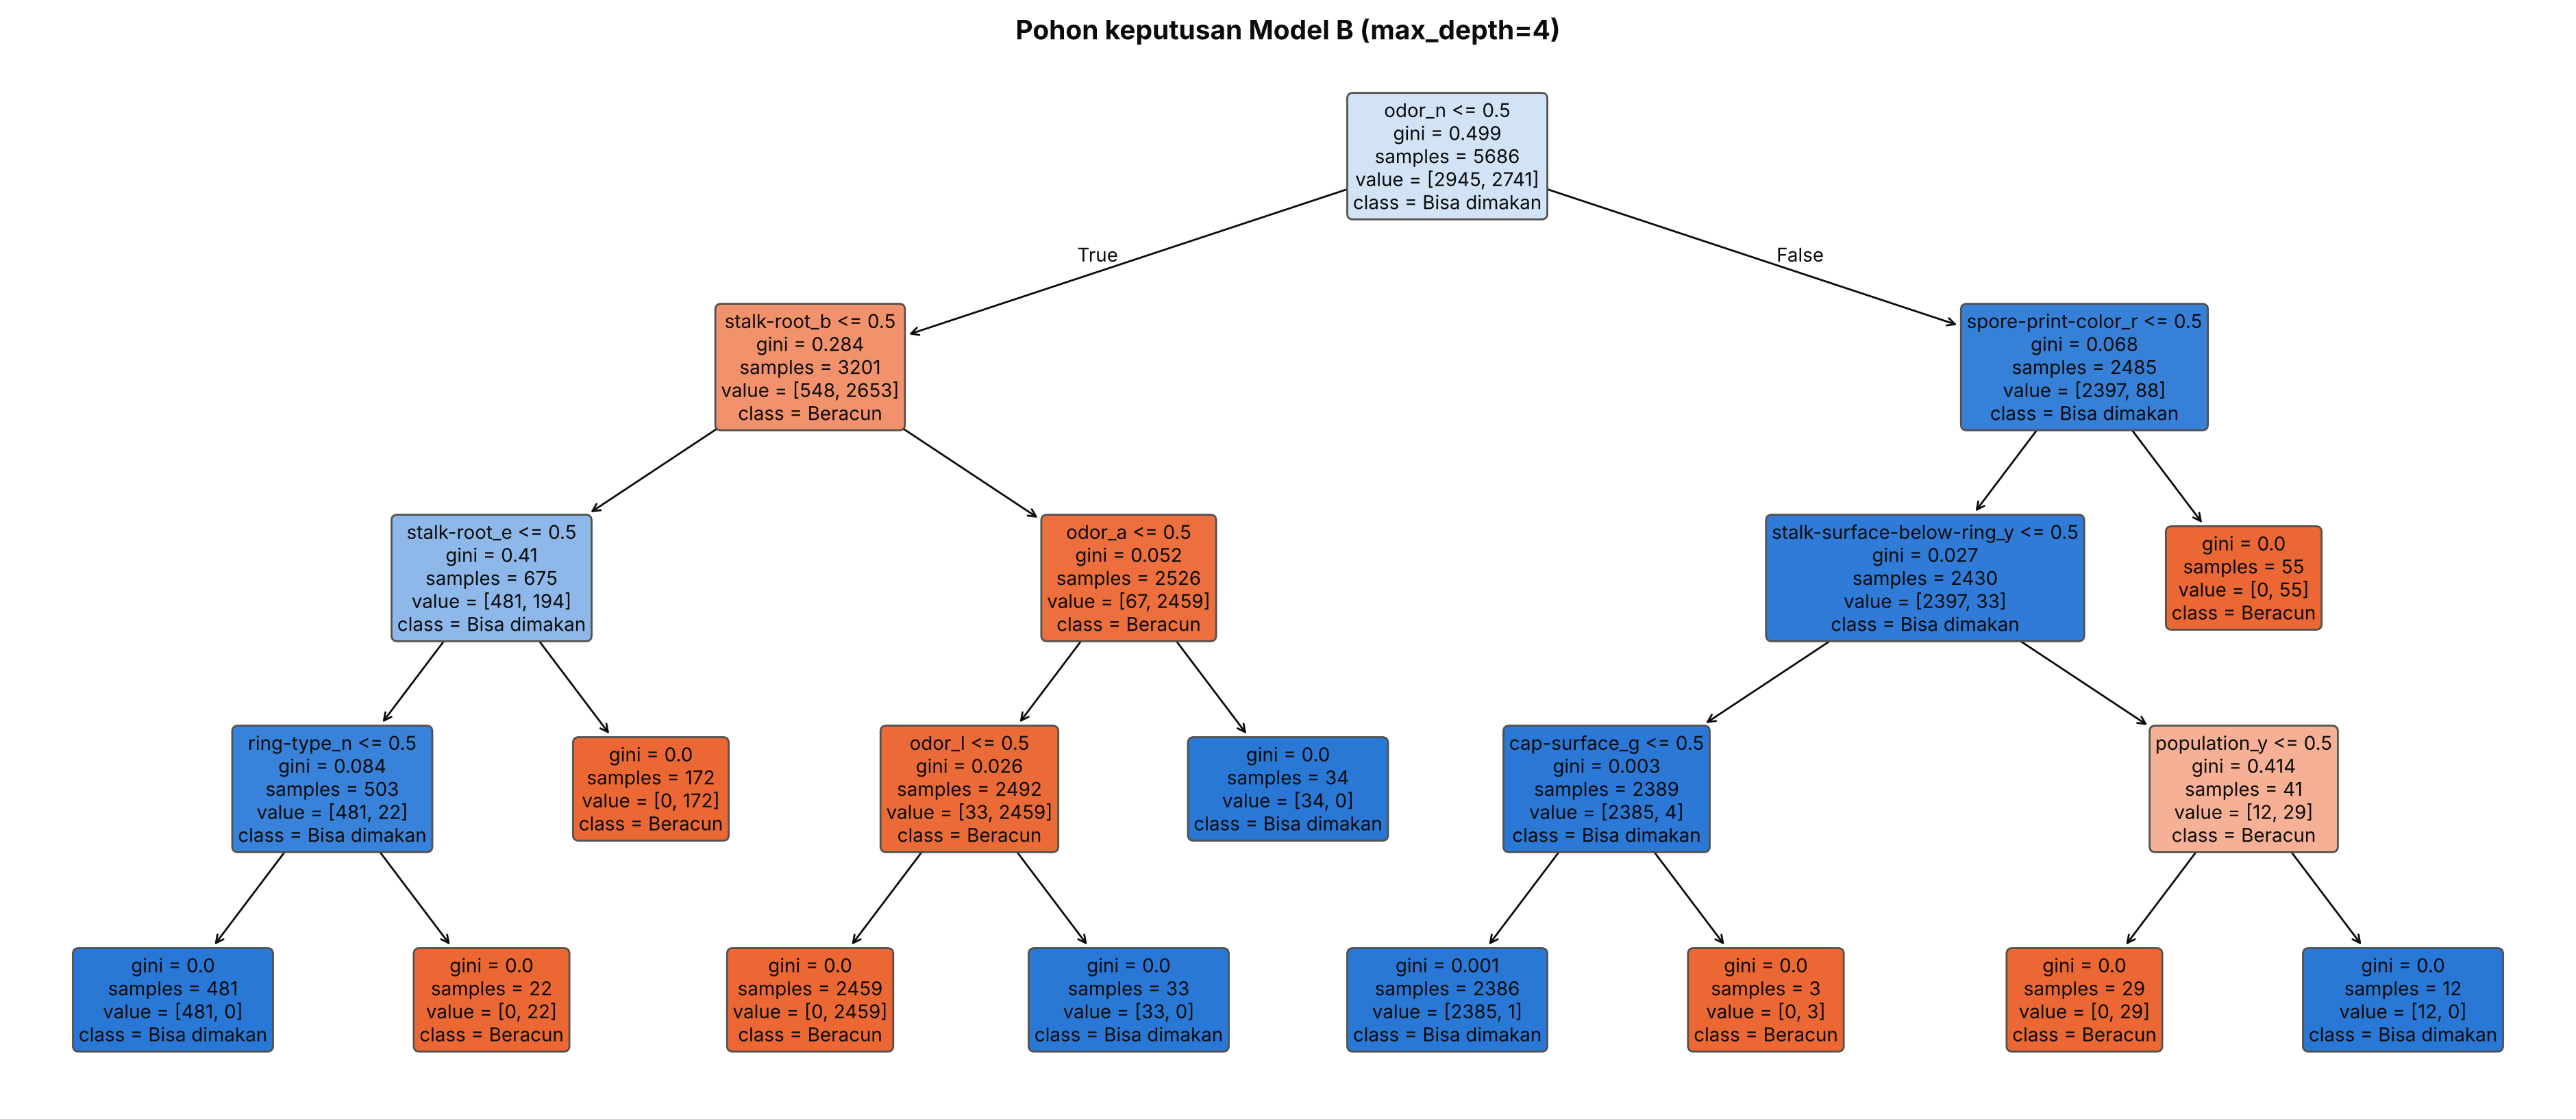

In [13]:
nama_fitur = list(model_b.named_steps["pra"].get_feature_names_out())
pohon_b = model_b.named_steps["pohon"]

fig, ax = plt.subplots(figsize=(24, 10))
anotasi = plot_tree(pohon_b, feature_names=nama_fitur, class_names=NAMA_KELAS,
                    filled=True, rounded=True, fontsize=10, impurity=True, ax=ax)

# Warna ulang node agar konsisten dengan grafik lain (biru = bisa dimakan, oranye = beracun);
# semakin pekat warna, semakin murni node tersebut.
nilai = pohon_b.tree_.value
anotasi_node = [a for a in anotasi if "samples" in a.get_text()]      # buang label panah True/False
assert len(anotasi_node) == pohon_b.tree_.node_count
for i, a in enumerate(anotasi_node):
    assert f"samples = {pohon_b.tree_.n_node_samples[i]}" in a.get_text()   # urutan anotasi = urutan node
    jumlah = nilai[i][0]
    kelas, kemurnian = int(np.argmax(jumlah)), float(np.max(jumlah) / np.sum(jumlah))
    dasar = np.array(to_rgb(ORANYE if kelas == 1 else BIRU))
    alfa = 0.18 + 0.82 * (kemurnian - 0.5) / 0.5
    warna = tuple(1 - alfa * (1 - dasar))
    a.get_bbox_patch().set_facecolor(warna)
    a.get_bbox_patch().set_edgecolor(INK2)
    a.set_color(INK)
ax.set_title("Pohon keputusan Model B (max_depth=4)", fontsize=14, loc="center")
ax.grid(False)
simpan("06_pohon_model_b")

### 6.2 Aturan jika-maka dari pohon

In [14]:
def ekstrak_aturan(pipeline):
    pohon = pipeline.named_steps["pohon"].tree_
    nama = list(pipeline.named_steps["pra"].get_feature_names_out())
    aturan = []
    def telusuri(node, syarat):
        if pohon.children_left[node] == pohon.children_right[node]:       # daun
            jumlah = pohon.value[node][0]
            aturan.append(dict(syarat=syarat, prediksi=int(np.argmax(jumlah)),
                               sampel=int(pohon.n_node_samples[node]),
                               kemurnian=float(np.max(jumlah) / np.sum(jumlah))))
            return
        kol = nama[pohon.feature[node]]
        telusuri(pohon.children_left[node], syarat + [jelaskan_kondisi(kol, False)])   # <= 0.5 -> kolom bernilai 0
        telusuri(pohon.children_right[node], syarat + [jelaskan_kondisi(kol, True)])   # >  0.5 -> kolom bernilai 1
    telusuri(0, [])
    return sorted(aturan, key=lambda r: -r["sampel"])

aturan_b = ekstrak_aturan(model_b)
print(f"Model B memiliki {len(aturan_b)} daun (aturan). Seluruh aturan, diurutkan dari yang paling banyak sampelnya:\n")
for i, r in enumerate(aturan_b, 1):
    print(f"Aturan {i:2d}: JIKA " + " DAN ".join(r["syarat"]))
    print(f"           MAKA {KELAS['p' if r['prediksi'] else 'e'].upper():12s} "
          f"({r['sampel']} sampel latih, kemurnian {r['kemurnian']:.1%})\n")

Model B memiliki 11 daun (aturan). Seluruh aturan, diurutkan dari yang paling banyak sampelnya:

Aturan  1: JIKA Bau ≠ Tidak berbau DAN Pangkal batang = Membulat DAN Bau ≠ Almond DAN Bau ≠ Adas manis
           MAKA BERACUN      (2459 sampel latih, kemurnian 100.0%)

Aturan  2: JIKA Bau = Tidak berbau DAN Warna cetakan spora ≠ Hijau DAN Permukaan batang bawah cincin ≠ Bersisik DAN Permukaan tudung ≠ Beralur
           MAKA BISA DIMAKAN (2386 sampel latih, kemurnian 100.0%)

Aturan  3: JIKA Bau ≠ Tidak berbau DAN Pangkal batang ≠ Membulat DAN Pangkal batang ≠ Rata DAN Tipe cincin ≠ Tidak ada
           MAKA BISA DIMAKAN (481 sampel latih, kemurnian 100.0%)

Aturan  4: JIKA Bau ≠ Tidak berbau DAN Pangkal batang ≠ Membulat DAN Pangkal batang = Rata
           MAKA BERACUN      (172 sampel latih, kemurnian 100.0%)

Aturan  5: JIKA Bau = Tidak berbau DAN Warna cetakan spora = Hijau
           MAKA BERACUN      (55 sampel latih, kemurnian 100.0%)

Aturan  6: JIKA Bau ≠ Tidak berbau DAN Pangk

**Tiga jalur yang dipilih untuk dijelaskan di laporan** (dua jalur terbesar dan satu jalur kecil yang menarik):

1. **Aturan 2 (bisa dimakan, 2.386 sampel latih):** JIKA bau = tidak berbau DAN warna cetakan spora bukan hijau DAN permukaan batang bawah cincin bukan bersisik DAN permukaan tudung bukan beralur, MAKA *bisa dimakan*.
2. **Aturan 1 (beracun, 2.459 sampel latih):** JIKA bau bukan tidak berbau DAN pangkal batang = membulat DAN bau bukan almond DAN bukan adas manis, MAKA *beracun*. Artinya jamur yang berbau (busuk, amis, menyengat, dan sejenisnya) dan berpangkal membulat dinilai beracun.
3. **Aturan 5 (beracun, 55 sampel latih):** JIKA bau = tidak berbau DAN warna cetakan spora = hijau, MAKA *beracun*. Ini jalur pendek yang menangkap jamur beracun tak berbau, yaitu kasus yang justru paling mudah terlewat jika hanya melihat baunya.

Catatan: karena nilai hilang `stalk-root` diisi dengan modus (`b` = membulat), sekitar 30% data ikut terhitung sebagai "pangkal batang membulat" pada aturan-aturan di atas.

### 6.3 Feature importance

Pentingnya per fitur asli (jumlah dari kolom one-hot-nya):
fitur
odor                        0.6667
stalk-root                  0.2593
spore-print-color           0.0369
ring-type                   0.0148
stalk-surface-below-ring    0.0141
population                  0.0060
cap-surface                 0.0021

Kolom one-hot yang paling berpengaruh:
              kolom  penting
             odor_n   0.6207
       stalk-root_b   0.1767
       stalk-root_e   0.0826
spore-print-color_r   0.0369
             odor_a   0.0230
             odor_l   0.0230


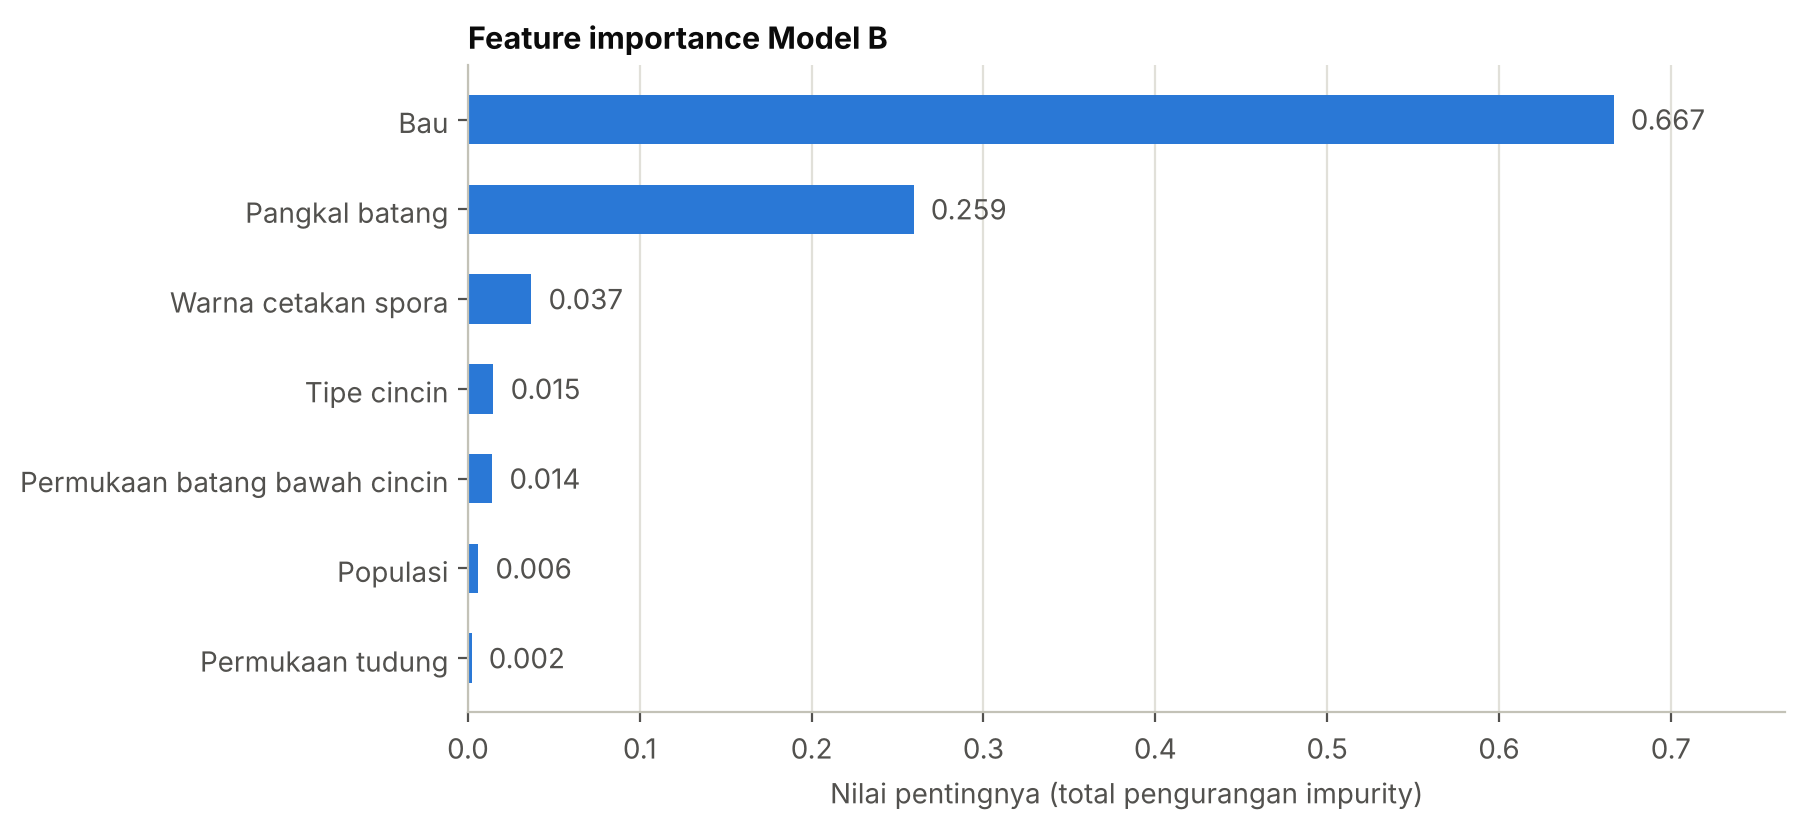

In [15]:
imp = pd.DataFrame({"kolom": nama_fitur, "penting": pohon_b.feature_importances_})
imp["fitur"] = imp["kolom"].map(lambda k: pisah_ohe(k)[0])
imp_fitur = imp.groupby("fitur")["penting"].sum().sort_values(ascending=False)
imp_fitur = imp_fitur[imp_fitur > 0]
print("Pentingnya per fitur asli (jumlah dari kolom one-hot-nya):")
print(imp_fitur.round(4).to_string())
print("\nKolom one-hot yang paling berpengaruh:")
print(imp.sort_values("penting", ascending=False).head(6)[["kolom", "penting"]].round(4).to_string(index=False))

fig, ax = plt.subplots(figsize=(8.5, 4.2))
y_pos = np.arange(len(imp_fitur))[::-1]
ax.barh(y_pos, imp_fitur.values, color=BIRU, height=0.55)
for yp, v in zip(y_pos, imp_fitur.values):
    ax.text(v + 0.01, yp, f"{v:.3f}", va="center", fontsize=10, color=INK2)
ax.set_yticks(y_pos); ax.set_yticklabels([judul_pendek(f) for f in imp_fitur.index])
ax.set_xlim(0, imp_fitur.max() * 1.15)
ax.set_xlabel("Nilai pentingnya (total pengurangan impurity)")
ax.set_title("Feature importance Model B")
ax.grid(axis="y", visible=False); ax.grid(axis="x")
simpan("07_feature_importance")

## 7. Penyimpanan model dan metrik

In [16]:
joblib.dump(model_a, "../model/jamur_dt_model_a.joblib")
joblib.dump(model_b, "../model/jamur_dt_model_b.joblib")

# Contoh input nyata (dari data uji) untuk tombol contoh di aplikasi: yakin, diprediksi benar oleh Model B, dan stalk-root diketahui
proba = model_b.predict_proba(X_test)[:, 1]
benar = model_b.predict(X_test) == y_test.values
def ambil(kelas):
    idx = np.where((y_test.values == kelas) & benar & (np.abs(proba - kelas) < 0.01) & (X_test["stalk-root"].values != "?"))[0][0]
    return X_test.iloc[idx].to_dict()
contoh = {"aman": ambil(0), "beracun": ambil(1)}
json.dump(contoh, open("../model/contoh_input.json", "w"), ensure_ascii=False, indent=2)

metrik = {
    "n_total": int(len(df)), "n_latih": int(len(X_train)), "n_uji": int(len(X_test)),
    "kelas": {"e": int((df["class"] == "e").sum()), "p": int((df["class"] == "p").sum())},
    "stalk_root_hilang": int((df["stalk-root"] == "?").sum()), "modus_stalk_root": modus_stalk_root,
    "gini_awal": float(gini_awal), "gini_top5": gini_fitur.head(5).round(4).to_dict(),
    "model_a": {k: v for k, v in hasil["A"].items() if k != "pred_test"},
    "model_b": {k: v for k, v in hasil["B"].items() if k != "pred_test"},
    "cv_a": [float(v) for v in cv_a], "cv_b": [float(v) for v in cv_b],
    "sapuan_kedalaman": sapuan.to_dict(orient="list"),
    "importance": {k: float(v) for k, v in imp_fitur.items()},
    "aturan_b": aturan_b,
    "report_b": classification_report(y_test, hasil["B"]["pred_test"], target_names=NAMA_KELAS, output_dict=True),
    "report_a": classification_report(y_test, hasil["A"]["pred_test"], target_names=NAMA_KELAS, output_dict=True),
}
json.dump(metrik, open("../model/metrik.json", "w"), ensure_ascii=False, indent=2)
print("Tersimpan:", sorted(os.listdir("../model")))
print("Ukuran model B:", round(os.path.getsize("../model/jamur_dt_model_b.joblib") / 1024, 1), "KB")

Tersimpan: ['contoh_input.json', 'jamur_dt_model_a.joblib', 'jamur_dt_model_b.joblib', 'metrik.json']
Ukuran model B: 8.9 KB


## 8. Kesimpulan

1. **Decision Tree sangat cocok untuk dataset jamur.** Beberapa ciri fisik, terutama **bau**, disusul pangkal batang dan warna cetakan spora, hampir cukup untuk memisahkan jamur beracun dari yang bisa dimakan.
2. **Model A (tanpa batas) tidak overfit pada dataset ini.** Akurasi latih dan uji sama-sama 100% dengan kedalaman 6. Ini temuan penting: overfitting bukan keniscayaan, dan sangat bergantung pada seberapa terpisah kelasnya.
3. **Model B (max_depth=4)** lebih ringkas dan mudah dijelaskan, dengan akurasi uji sedikit lebih rendah serta 3 jamur beracun yang lolos sebagai "aman". Pada konteks keselamatan, kesalahan jenis ini patut dihindari.
4. **Pemilihan model untuk aplikasi** dibuat dengan mempertimbangkan akurasi uji, hasil validasi silang, dan jumlah False Negative. Pada data ini Model A unggul di ketiganya; Model B unggul dalam kesederhanaan aturan.
5. Aplikasi hanyalah alat bantu belajar dan **tidak boleh dijadikan dasar memutuskan apakah suatu jamur aman dikonsumsi**.